In [2]:
import pandas as pd
import numpy as np
import  matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
from scipy.stats import linregress

from scipy.io import loadmat
import h5py


## **Data Loading**

In [3]:
data = loadmat("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/fitting/M5_FRINT_Fit/LucasBenjamin_5a9c41f2dbdb470001eeef9c_M5_VBMC.mat")
out = data["out_vbmc"][0,0]

## **Exploring Dataset Matlab**

In [4]:
print(out.dtype.names)

('s_sen', 'g_sen', 's_rot', 'd_rot_p', 'd_rot_m', 's_fac', 'w_fac_p', 'w_fac_m', 's_int', 'l_int', 's_rep', 'p_lap', 'pnam', 'pmap', 'pavg', 'fitalgo', 'version', 'tfit', 'nsmp', 'nres', 'nobs', 'nfit', 'vp', 'elbo', 'elbo_sd', 'xnam', 'xmap', 'xavg', 'xstd', 'xcov', 'xmed', 'xqrt', 'xc95', 'xnam_all', 'xhat_all', 'options', 'output', 'tss', 'ess', 'zang_f', 'zabs_f', 'xcon_f', 'zang_u', 'zabs_u', 'xcon_u')


In [5]:
# to get the name of a parameter :
print([str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()])

# to get the value of a parameter :
print(out["xavg"].squeeze())

# to get one item from the file : 
print(out["g_sen"].item())

# to get the list of items of a parameter : 
print(out["pmap"][0].item())

['g_sen', 's_rot', 'd_rot_p', 'd_rot_m', 'w_fac_p', 'w_fac_m', 's_int', 'l_int', 's_rep']
[ 0.63433461  0.38234764  0.77842035 -0.63712435  0.34348909  0.22695099
  0.24461054  0.46630471  0.35964481]
0.6343346126390547
(array([[0]], dtype=uint8), array([[0.59565821]]), array([[0.32844894]]), array([[0.75808252]]), array([[-0.64484873]]), array([[0]], dtype=uint8), array([[0.27580335]]), array([[0.04027514]]), array([[0.27218877]]), array([[0.34341657]]), array([[0.34610924]]), array([[0]], dtype=uint8))


## **Info and Dataframes**

In [9]:
tfit = out["tfit"][0].item()
print("total fitting time =", tfit)
nfit = out["nfit"][0].item()
print("number of fitted parameters =", nfit)
xnam = out["xnam"][0]
print("the name of fitted parameters are :", [str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()])

total fitting time = 2943.41071775
number of fitted parameters = 9
the name of fitted parameters are : ['g_sen', 's_rot', 'd_rot_p', 'd_rot_m', 'w_fac_p', 'w_fac_m', 's_int', 'l_int', 's_rep']


In [7]:
parameters = pd.DataFrame(index= [str(x[0]) if len(x) > 0 else "" for x in out["pnam"].squeeze()], columns =  ["value"])
for column, num in zip([str(x[0]) if len(x) > 0 else "" for x in out["pnam"].squeeze()], range(12)) : 
    parameters.loc[column] = out[num].item()

parameters["mod"] = np.squeeze(out["pmap"][0].item())
parameters["average"] = np.squeeze(out["pavg"][0].item())

parameters


,value,mod,average
s_sen,0,0.000000,0.000000
g_sen,0.634335,0.595658,0.634335
s_rot,0.382348,0.328449,0.382348
d_rot_p,0.77842,0.758083,0.778420
d_rot_m,-0.637124,-0.644849,-0.637124
s_fac,0,0.000000,0.000000
w_fac_p,0.343489,0.275803,0.343489
w_fac_m,0.226951,0.040275,0.226951
s_int,0.244611,0.272189,0.244611
l_int,0.466305,0.343417,0.466305


In [ ]:
fitted_parameters = pd.DataFrame(index= [str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()], columns =  ["average", "mod", "std","median", "Q1", "Q3", "c95_left", "c95_right"])
for column, num in zip([str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()], range(12)) : 
    fitted_parameters["average"] = out["xavg"].squeeze()
    fitted_parameters["mod"] = out["xmap"].squeeze()
    fitted_parameters["std"] = out["xstd"].squeeze()
    fitted_parameters["median"] = out["xmed"].squeeze()
    fitted_parameters["Q1"] = out["xqrt"].squeeze()[0]
    fitted_parameters["Q3"] = out["xqrt"].squeeze()[1]
    fitted_parameters["c95_left"] = out["xc95"].squeeze()[0]
    fitted_parameters["c95_right"] = out["xc95"].squeeze()[1]

fitted_parameters

,average,mod,std,median,Q1,Q3,c95_left,c95_right
g_sen,0.488229,0.456981,0.113639,0.487282,0.411461,0.563991,0.267987,0.714129
s_rot,0.083777,0.010519,0.043998,0.082797,0.052507,0.111998,0.009826,0.176437
d_rot_p,0.703247,0.705712,0.040018,0.703777,0.676494,0.730522,0.623594,0.780176
d_rot_m,-0.635651,-0.632749,0.033317,-0.635915,-0.658145,-0.613492,-0.700300,-0.569520
w_fac_p,0.326411,0.260998,0.118579,0.313254,0.242276,0.396434,0.130629,0.595249
w_fac_m,0.625212,0.534751,0.155919,0.608911,0.513557,0.719174,0.367962,0.974289
s_int,0.587565,0.574433,0.066156,0.584531,0.541520,0.630127,0.466825,0.726034
l_int,0.176098,0.120153,0.084159,0.171976,0.120732,0.226630,0.019376,0.357893
s_rep,0.081943,0.103636,0.022916,0.081636,0.066642,0.096791,0.036600,0.128550


## **for all subjects**

In [10]:
filepaths = glob.glob("/Users/elodiehusson/Desktop/Projet/comportement AVANT STAGE/fitting/M5_FRINT_Fit/*M5*VBMC.mat")
outs = [loadmat(f)["out_vbmc"][0,0] for f in filepaths]

In [54]:
param_names = [str(x[0]) if len(x) > 0 else "" for x in outs[0]["xnam"].squeeze()]

# créer un DataFrame vide pour chaque paramètre
for param in param_names:
    globals()[f"{param}_all"]= pd.DataFrame(columns=["average", "mod", "std", "median", "Q1", "Q3", "c95_left", "c95_right"])

for i, out in enumerate(outs):
    fitted_parameters = pd.DataFrame(
        index=[str(x[0]) if len(x) > 0 else "" for x in out["xnam"].squeeze()],
        columns=["average", "mod", "std", "median", "Q1", "Q3", "c95_left", "c95_right"]
    )

    fitted_parameters["average"]   = out["xavg"].squeeze()
    fitted_parameters["mod"]       = out["xmap"].squeeze()
    fitted_parameters["std"]       = out["xstd"].squeeze()
    fitted_parameters["median"]    = out["xmed"].squeeze()
    fitted_parameters["Q1"]        = out["xqrt"].squeeze()[0]
    fitted_parameters["Q3"]        = out["xqrt"].squeeze()[1]
    fitted_parameters["c95_left"]  = out["xc95"].squeeze()[0]
    fitted_parameters["c95_right"] = out["xc95"].squeeze()[1]

    for param in fitted_parameters.index:
        globals()[f"{param}_all"] = pd.concat(
            [globals()[f"{param}_all"], fitted_parameters.loc[[param]]],
            axis=0,
            ignore_index=True
        )


/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_56762/444516688.py:23: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  globals()[f"{param}_all"] = pd.concat(
/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_56762/444516688.py:23: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  globals()[f"{param}_all"] = pd.concat(
/var/folders/k4/d0pwylgd1tl4mf2_hqnm6l400000gn/T/ipykernel_56762/444516688.py:23: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries 

In [55]:
g_sen_all

,average,mod,std,median,Q1,Q3,c95_left,c95_right
0,0.559325,0.561647,0.231216,0.556360,0.403249,0.711244,0.113478,1.026418
1,0.726039,0.724175,0.165407,0.726975,0.615484,0.837601,0.399016,1.048259
2,0.876875,0.897226,0.163573,0.877540,0.767541,0.987566,0.553438,1.194705
3,1.327599,1.447364,0.271291,1.325507,1.146471,1.507244,0.801438,1.867459
4,0.891952,0.855419,0.183624,0.892937,0.768461,1.016619,0.530243,1.249188
...,...,...,...,...,...,...,...,...
99,0.564106,0.533723,0.112909,0.562727,0.487815,0.639348,0.345250,0.788874
100,0.252385,0.237787,0.169607,0.252268,0.139602,0.364897,-0.081303,0.586897
101,0.353316,0.399984,0.322647,0.352955,0.137895,0.568713,-0.280467,0.988677
102,-0.502325,-0.567325,0.210991,-0.505415,-0.646016,-0.362162,-0.906916,-0.079125


[]

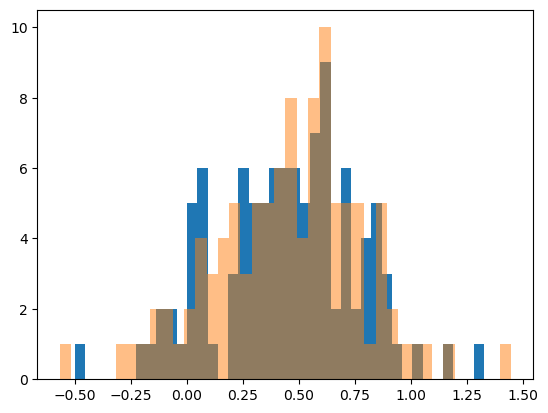

In [65]:
plt.hist(g_sen_all["average"], bins=40)
plt.hist(g_sen_all["mod"], bins=40, alpha = 0.5)
plt.plot()